In [166]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rc('font', **{'family':'sans-serif','sans-serif':['Arial'], 'size': 8})
plt.rcParams.update({
    "font.size": 8, "axes.labelsize": 8, "axes.titlesize": 8, "xtick.labelsize": 7, "ytick.labelsize": 7,
    "legend.fontsize": 7, "font.family": "sans-serif", "axes.linewidth": 0.7, "xtick.major.width": 0.7,
    "ytick.major.width": 0.7, "xtick.major.size": 3.0, "ytick.major.size": 3.0, "savefig.dpi": 600,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})


hexcolors = [
    '#D1B8D7', '#AE76A3', '#882E72',
    '#1965B0', '#5289C7', '#7BAFDE',
    '#4EB265', '#90C987', '#CAE0AB',
    '#F7F056', '#F6C141', '#F1932D',
    '#E8601C', '#DC050C', '#777777',
    '#000000'
]
 
colornames = ['purple1','purple2','purple3',
    'blue1','blue2','blue3',
    'green1','green2','green3',
    'yellow1','yellow2','orange1',
    'orange2','red','grey', 'black']
 
rnb_colors = dict(zip(colornames, hexcolors))

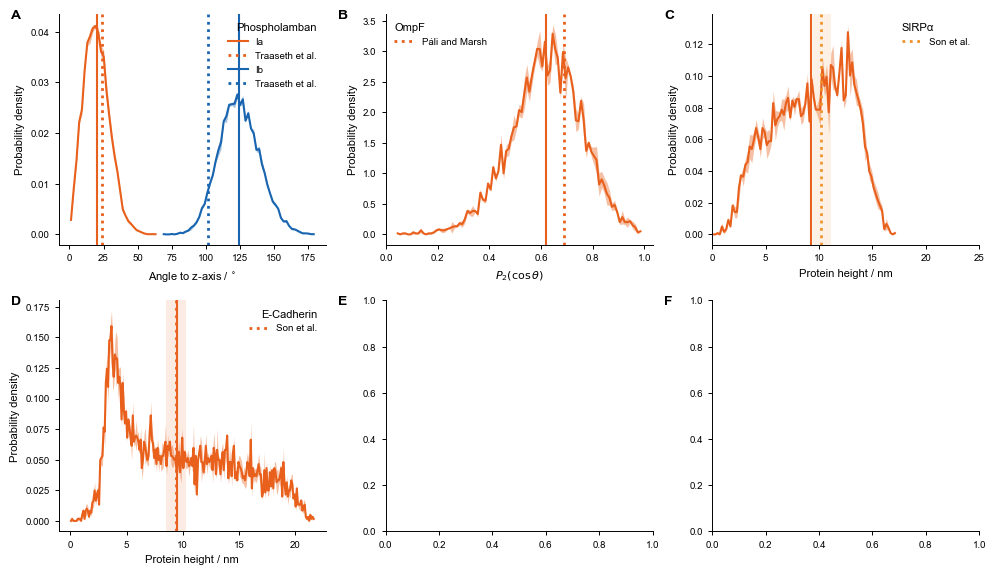

In [168]:
def hist_stats(xs, bins):
    h = np.array([np.histogram(x, bins=bins, density=True)[0] for x in xs])
    p = np.histogram(np.concatenate(xs), bins=bins, density=True)[0]
    x = (bins[:-1] + bins[1:]) / 2
    return x, p, h.std(0)/np.sqrt(len(xs)), np.concatenate(xs).mean()

fig, ax = plt.subplots(2, 3, figsize=(10, 5.8))
ax = ax.ravel()

# --- phospholamban (2KB7) ---
a1, a2 = [], []
for i in range(3):
    d = np.load(f'data/exp_valid/2KB7_{i}_domain_angles.npy', allow_pickle=True).item()
    a1.append(np.minimum(d['TMD'][100:], 180 - d['TMD'][100:]))
    if i == 1:
        a2.append(180 - d['la'][100:])
    else:
        a2.append(d['la'][100:])

"""bins = np.arange(np.floor(min(np.concatenate(a1).min(), np.concatenate(a2).min())),
                 np.ceil(max(np.concatenate(a1).max(), np.concatenate(a2).max())) + 2, 2)

for y in a2:
    x = (bins[:-1] + bins[1:]) / 2
    ax[0].plot(x,np.histogram(y, bins=bins, density=True)[0])"""

for arr, c, lab, exp, explab in [(a1, 'orange2', 'Ia', 24,  'Traaseth et al.'),
                                 (a2, 'blue1',   'Ib', 102, 'Traaseth et al.')]:
    bins = np.arange(np.min(arr),np.max(arr) + 2, 2)
    x, p, se, m = hist_stats(arr, bins)
    ax[0].plot(x, p, color=rnb_colors[c], lw=1.5, label=lab)
    ax[0].fill_between(x, p-se, p+se, color=rnb_colors[c], alpha=.4, lw=0)
    ax[0].axvline(m, color=rnb_colors[c], lw=1.5)
    ax[0].axvline(exp, color=rnb_colors[c], ls=':', lw=2, label=explab)

ax[0].set(xlabel='Angle to z-axis / $^{\\circ}$', ylabel='Probability density')
leg = ax[0].legend(frameon=False, fontsize=7, title='Phospholamban')
leg._legend_box.align = "right"

# --- 2OMF ---
p2 = []
for i in range(3):
    a = np.load(f'data/exp_valid/2OMF_{i}_domain_angles.npy', allow_pickle=True).item()['TMD'][100:, 0]
    p2.append(0.5 * (3*np.cos(np.radians(a))**2 - 1))

bins = np.arange(np.floor(np.concatenate(p2).min()*100)/100,
                 np.ceil(np.concatenate(p2).max()*100)/100 + 0.01, 0.01)
x, p, se, m = hist_stats(p2, bins)

ax[1].plot(x, p, color=rnb_colors['orange2'], lw=1.5)
ax[1].fill_between(x, p-se, p+se, color=rnb_colors['orange2'], alpha=.4, lw=0)
ax[1].axvline(m, color=rnb_colors['orange2'], lw=1.5)
ax[1].axvline(0.69, color=rnb_colors['orange2'], ls=':', lw=2, label='Páli and Marsh')
ax[1].set(xlabel=r'$P_2(\cos\theta)$', ylabel='Probability density')
leg = ax[1].legend(frameon=False, fontsize=7, title='OmpF')
leg._legend_box.align = "left"

# --- Sirpa ---
sirpa = [np.load(f'data/exp_valid/Sirpa_{i}_height.npy') for i in range(3)]
bins = np.arange(0, np.concatenate(sirpa).max() + 0.2, 0.2)
x, p, se, m = hist_stats(sirpa, bins)
ax[2].plot(x, p, color=rnb_colors['orange2'], lw=1.5)
ax[2].fill_between(x, p-se, p+se, color=rnb_colors['orange2'], alpha=.4, lw=0)
ax[2].axvline(m, color=rnb_colors['orange2'], lw=1.5)

for val, lo, hi, lab, color in [(10.2, 9.4, 11.1, 'Son et al.','orange1'),
                         (7.3,  6.4,  8.2, 'Son et al. (His$_{10}$)','blue1')][:1]:
    ax[2].axvline(val, color=rnb_colors[color], ls=':', lw=2, label=lab)
    ax[2].axvspan(lo, hi, color=rnb_colors[color], alpha=.12, lw=0)

ax[2].set(xlabel='Protein height / nm', ylabel='Probability density')
leg = ax[2].legend(frameon=False, fontsize=7, title='SIRPα')
leg._legend_box.align = "left"
ax[2].set_xlim(0,25)

# --- Cdh1 ---
cdh1 = [np.load(f'data/exp_valid/Cdh1_{i}_height.npy') for i in range(3)]
bins = np.arange(0, np.concatenate(cdh1).max() + 0.1, 0.1)
x, p, se, m = hist_stats(cdh1, bins)

ax[3].plot(x, p, color=rnb_colors['orange2'], lw=1.5)
ax[3].fill_between(x, p-se, p+se, color=rnb_colors['orange2'], alpha=.4, lw=0)
ax[3].axvline(m, color=rnb_colors['orange2'], lw=1.5)
ax[3].axvline(9.4, color=rnb_colors['orange2'], ls=':', lw=2, label='Son et al.')
ax[3].axvspan(8.5, 10.3, color=rnb_colors['orange2'], alpha=.12, lw=0)

ax[3].set(xlabel='Protein height / nm', ylabel='Probability density')
leg = ax[3].legend(frameon=False, fontsize=7, title='E-Cadherin')
leg._legend_box.align = "right"

"""
cutoff, area_nm2 = 1, 2*35*35/1e6
for chain, c, lab in [('aSyn', 'blue1', 'αSyn'), ('aSyn_LH', 'purple3', 'αSyn long helix')]:
    n = []
    for i in range(3):
        contacts = np.array([np.load(f'data/aSyn/{chain}_{i}_{j}_lipids_contacts.npy')
                             for j in range(1,17)]).T   # use range(1,17) if your files start at 1
        n.append((contacts >= cutoff).sum(1) / area_nm2)
    n = np.array([np.cumsum(x)/np.arange(1, len(x)+1) for x in n])
    t = np.arange(n.shape[1]) * 0.01 * 5e4 / 1e6
    ax[4].plot(t, n.mean(0), color=rnb_colors[c], lw=1.5, label=lab)
    ax[4].fill_between(t, n.mean(0)-n.std(0)/np.sqrt(3), n.mean(0)+n.std(0)/np.sqrt(3),
                       color=rnb_colors[c], alpha=.4, lw=0)

ax[4].axhline(1e4, color='k', ls=':', lw=2, label='Dubackic et al.')
ax[4].set(xlabel='Time / $\\mu$s', ylabel=r'Adsorbed αSyn proteins / $\mu$m$^{-2}$')
ax[4].legend(frameon=False, fontsize=7)

#
for chain, c, lab in [('aSyn', 'blue1', 'aSyn'), ('aSyn_LH', 'purple3', 'aSyn long helix')]:
    x = np.array([np.load(f'data/aSyn/{chain}_{i}_aSyn_tail_cmap.npy').sum(axis=1).reshape(16,140).mean(axis=0)
                  for i in range(3)])
    r = np.arange(1, 141)
    ax[5].plot(r, x.mean(0), color=rnb_colors[c], lw=1.5, label=lab)
    ax[5].fill_between(r, x.mean(0)-x.std(0)/np.sqrt(3), x.mean(0)+x.std(0)/np.sqrt(3),
                       color=rnb_colors[c], alpha=.4, lw=0)
    
ax[5].set(xlabel=r'$\alpha$Syn residue', ylabel='Normalized tail contacts')
ax[5].legend(frameon=False, fontsize=7)"""

for i, a in enumerate(ax):
    a.spines[['top', 'right']].set_visible(False)
    a.annotate(chr(65+i), (-.18, 0.98), xycoords='axes fraction', fontsize=10, weight='bold')

plt.tight_layout()
plt.savefig('5.pdf')
plt.show()